## Cell 0 - Setup and data loading

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from build_lagged_features import read_table, build_lagged_frame, DEFAULT_LAGS

df = read_table("../../data/chlorophyll_student_2015_2023.xlsx")
print(df.shape)
df.head()

(3287, 14)


,date,chlorophyll_a_mg_m3,sst_c,par_umol_m2_s,nitrate_umol_l,wind_speed_m_s,upwelling_index,mixed_layer_depth_m,salinity_psu,current_speed_m_s,river_discharge_index,cloud_fraction,surface_pressure_hpa,turbidity_ntu
0,2015-01-01,1.384479,11.481587,149.109963,6.015581,6.312241,0.888380,31.398514,35.267326,0.243345,1.454131,0.772424,1013.630651,2.712575
1,2015-01-02,1.163834,11.645005,102.709144,5.378356,6.419118,0.069684,32.582147,35.232201,0.305887,1.504132,0.720854,1013.746950,2.929409
2,2015-01-03,1.159372,11.306775,113.837502,6.347327,7.360378,1.600903,34.065341,35.221364,0.363735,1.290741,0.734412,1014.856950,2.631379
3,2015-01-04,1.370594,12.116982,173.914824,6.120668,7.730971,1.282715,34.538421,35.267070,0.402836,1.644759,0.642274,1013.131768,2.668686
4,2015-01-05,1.637080,11.822242,76.814006,5.257523,6.902393,0.519057,35.724733,35.329770,0.364641,1.234290,0.744293,1014.762930,2.520198


## Cell 1 - Basic exploratory plots

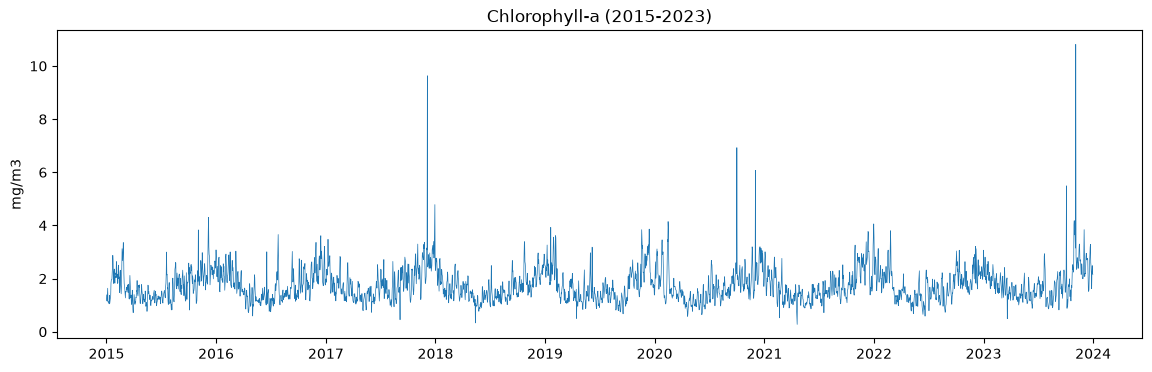

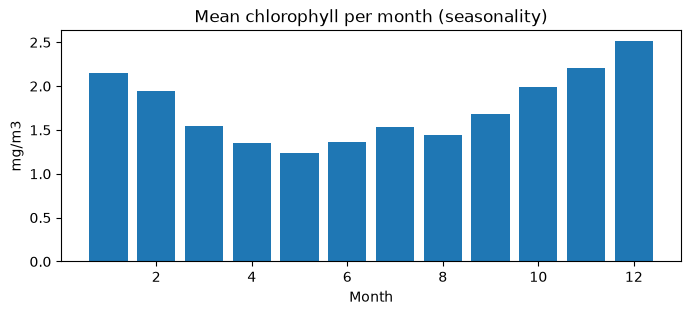

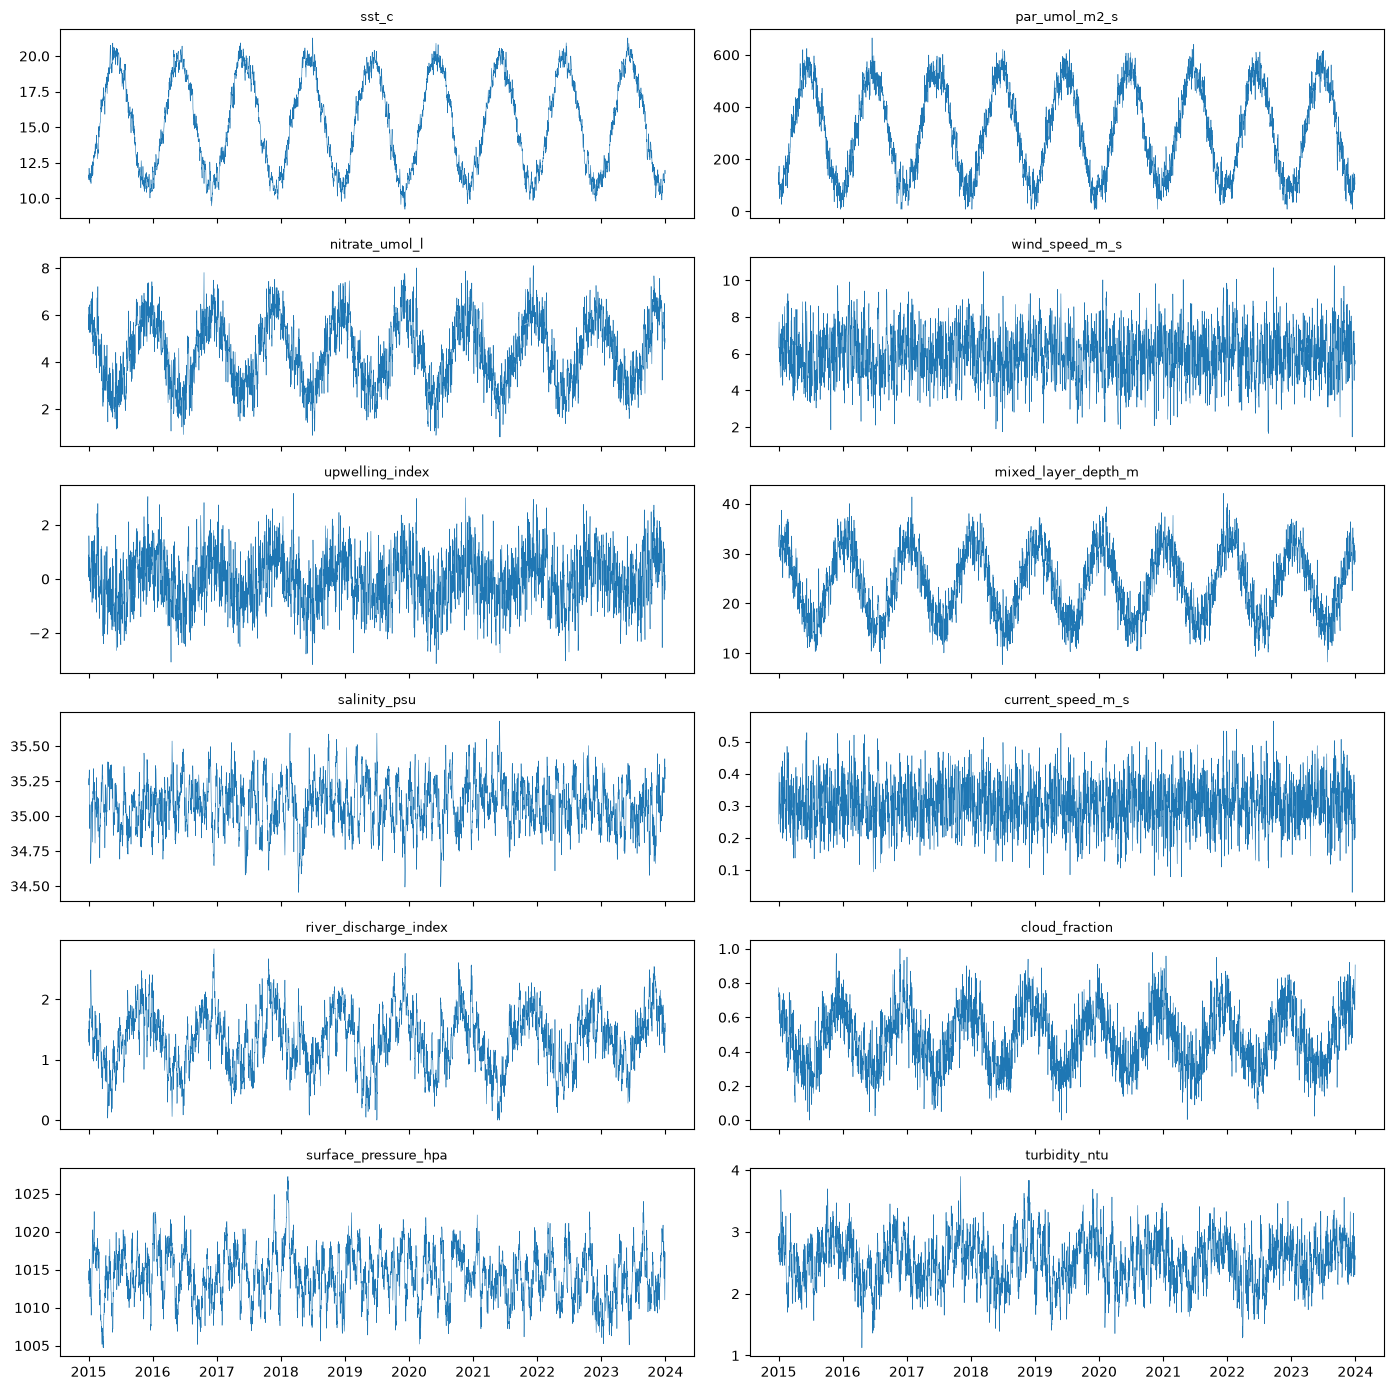

sst_c                   -0.587512
par_umol_m2_s           -0.562788
salinity_psu            -0.122307
surface_pressure_hpa     0.047198
current_speed_m_s        0.119091
wind_speed_m_s           0.223992
turbidity_ntu            0.285146
upwelling_index          0.401890
cloud_fraction           0.414014
mixed_layer_depth_m      0.455578
river_discharge_index    0.463456
nitrate_umol_l           0.581618
chlorophyll_a_mg_m3      1.000000
Name: chlorophyll_a_mg_m3, dtype: float64


In [87]:
# Chlorophyll over time (target)
plt.figure(figsize=(14, 4))
plt.plot(df["date"], df["chlorophyll_a_mg_m3"], lw=0.5)
plt.title("Chlorophyll-a (2015-2023)")
plt.ylabel("mg/m3")
plt.show()

# Seasonality: monthly mean
monthly = df.groupby(df["date"].dt.month)["chlorophyll_a_mg_m3"].mean()
plt.figure(figsize=(8, 3))
plt.bar(monthly.index, monthly.values)
plt.title("Mean chlorophyll per month (seasonality)")
plt.xlabel("Month")
plt.ylabel("mg/m3")
plt.show()

# Other variables over time
fig, axes = plt.subplots(6, 2, figsize=(14, 14), sharex=True)
for ax, col in zip(axes.flat, df.columns[2:]):
    ax.plot(df["date"], df[col], lw=0.4)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

# Correlation with the target
corr = df.drop(columns=["date"]).corr()["chlorophyll_a_mg_m3"].sort_values()
print(corr)

## Cell 2 - Correlation matrix (heatmap)

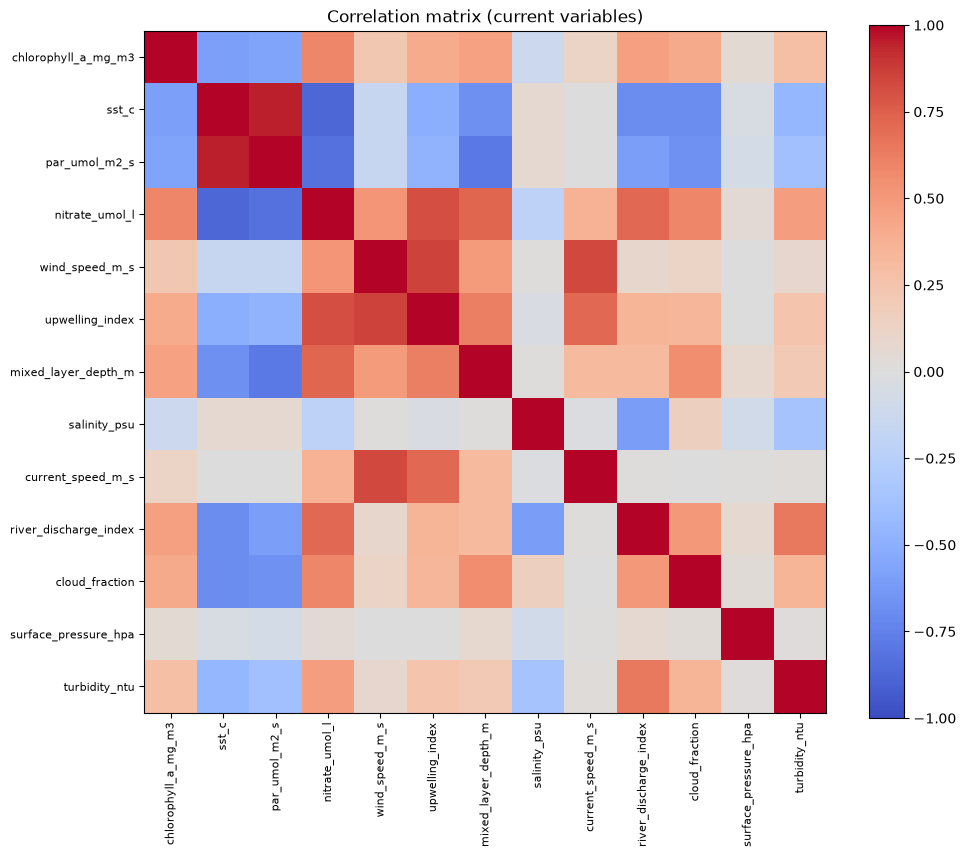

Top 15 correlated exogenous pairs:
sst_c                  par_umol_m2_s            0.950921
                       nitrate_umol_l          -0.872425
wind_speed_m_s         upwelling_index          0.853220
                       current_speed_m_s        0.834783
par_umol_m2_s          nitrate_umol_l          -0.825669
nitrate_umol_l         upwelling_index          0.808314
par_umol_m2_s          mixed_layer_depth_m     -0.785356
nitrate_umol_l         mixed_layer_depth_m      0.719860
upwelling_index        current_speed_m_s        0.718420
nitrate_umol_l         river_discharge_index    0.711903
sst_c                  river_discharge_index   -0.690080
                       cloud_fraction          -0.689309
                       mixed_layer_depth_m     -0.673652
par_umol_m2_s          cloud_fraction          -0.668036
river_discharge_index  turbidity_ntu            0.646423
dtype: float64


In [88]:
cols = df.drop(columns=["date"]).columns
corr_matrix = df[cols].corr()

plt.figure(figsize=(11, 9))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=90, fontsize=8)
plt.yticks(range(len(cols)), cols, fontsize=8)
plt.title("Correlation matrix (current variables)")
plt.show()

# Most correlated pairs of exogenous variables (multicollinearity)
corr_pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
              .stack().sort_values(key=abs, ascending=False))
print("Top 15 correlated exogenous pairs:")
print(corr_pairs.head(15))

## Cell 3 - Cross-correlation target vs exogenous per lag

Each panel shows corr(y(t), x(t-j)) for j = 0..21. The lag with the peak correlation indicates the response delay of that variable: this is the guide for choosing the lags q_k of each exogenous variable.

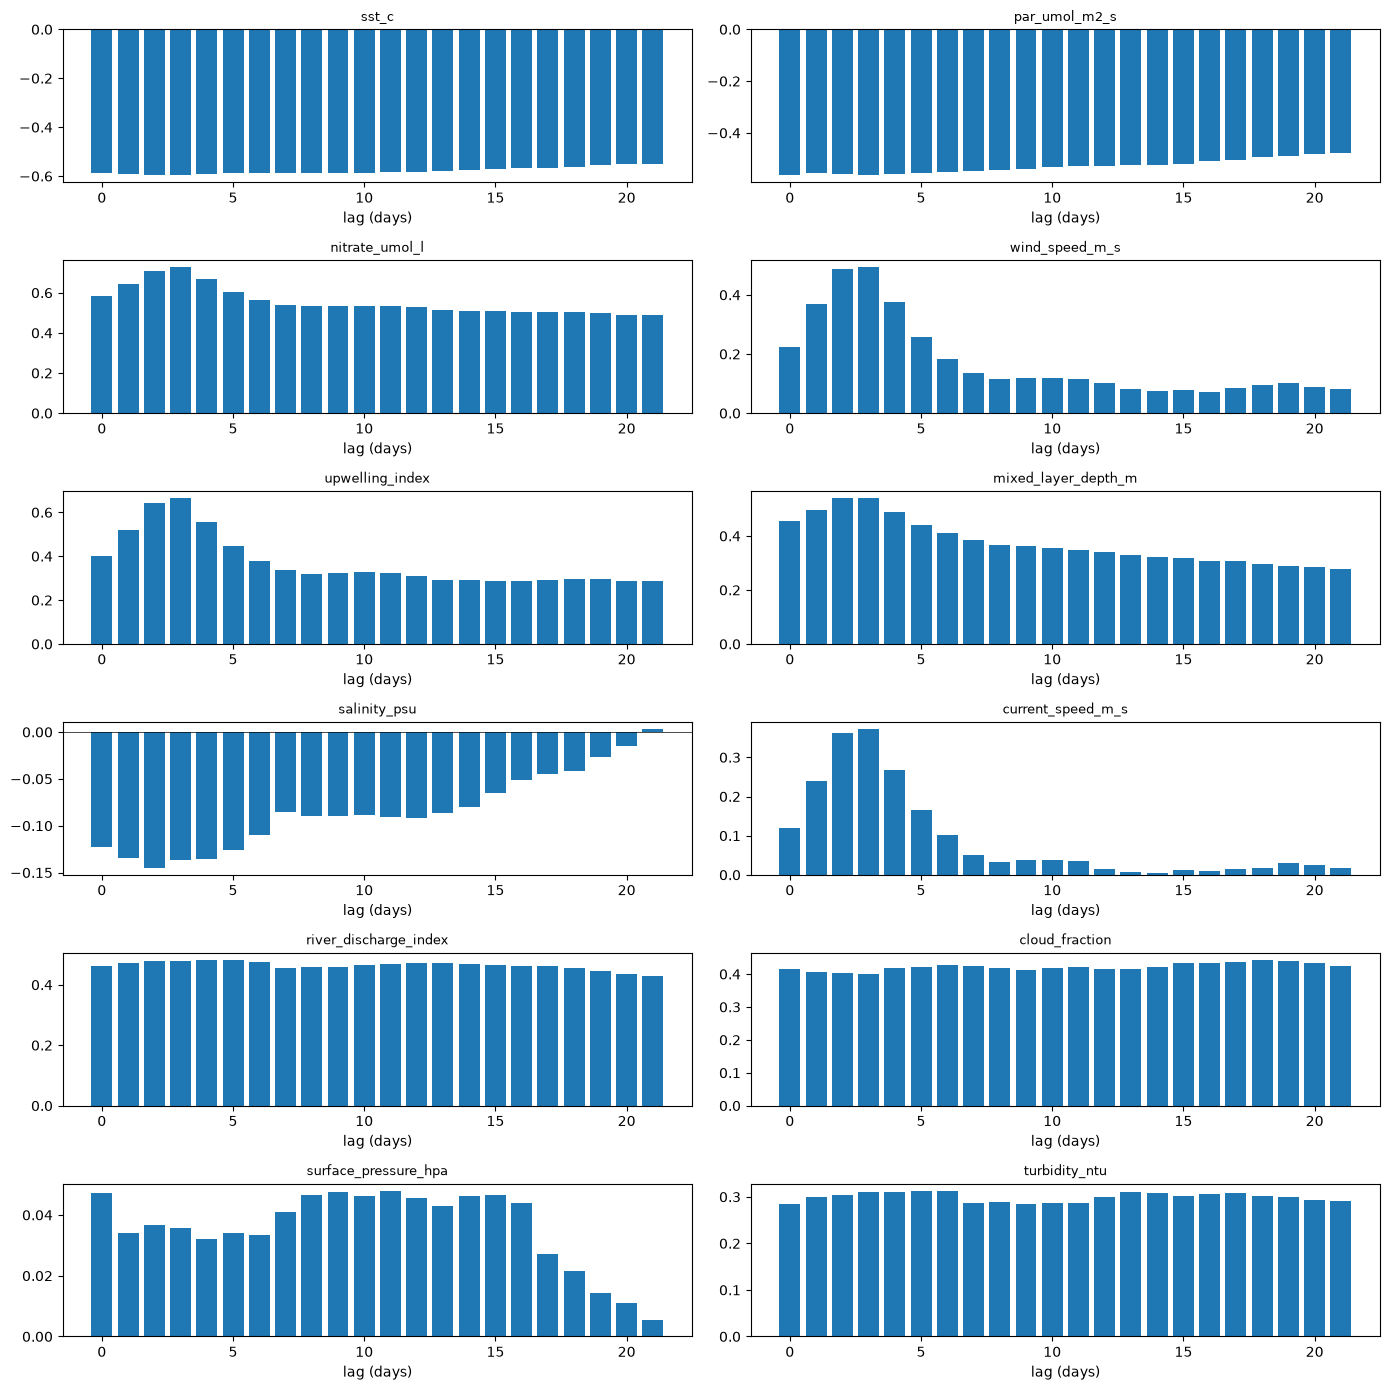

In [89]:
MAX_LAG = 21
exo_cols = [c for c in df.columns if c not in ("date", "chlorophyll_a_mg_m3")]

fig, axes = plt.subplots(6, 2, figsize=(14, 14))
for ax, col in zip(axes.flat, exo_cols):
    ccf = [df["chlorophyll_a_mg_m3"].corr(df[col].shift(j)) for j in range(MAX_LAG + 1)]
    ax.bar(range(MAX_LAG + 1), ccf)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("lag (days)")
plt.tight_layout()
plt.show()

## Cell 4 - Autocorrelation (ACF) and partial autocorrelation (PACF) of the target

AR lags outside the red significance band are the ones to keep for p.

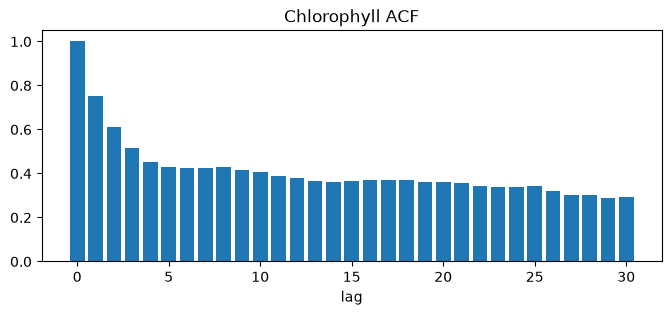

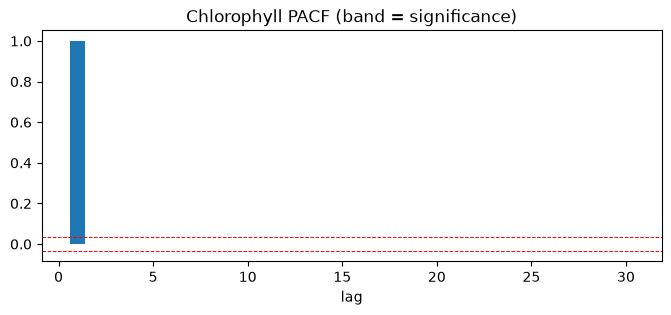

In [90]:
y_series = df["chlorophyll_a_mg_m3"]

# Simple autocorrelation
acf = [y_series.autocorr(lag=j) for j in range(31)]
plt.figure(figsize=(8, 3))
plt.bar(range(31), acf)
plt.title("Chlorophyll ACF")
plt.xlabel("lag")
plt.show()

# PACF: Yule-Walker solution with numpy (no external libraries)
from numpy.linalg import solve
r = np.array([y_series.autocorr(lag=j) for j in range(1, 31)])
pacf = []
for k in range(1, 31):
    R = np.array([[r[abs(i-j)] for j in range(k)] for i in range(k)])
    pacf.append(solve(R, r[:k])[-1])
plt.figure(figsize=(8, 3))
plt.bar(range(1, 31), pacf)
plt.axhline(1.96/np.sqrt(len(y_series)), color="red", ls="--", lw=0.7)
plt.axhline(-1.96/np.sqrt(len(y_series)), color="red", ls="--", lw=0.7)
plt.title("Chlorophyll PACF (band = significance)")
plt.xlabel("lag")
plt.show()

## Cell 5 - Outlier analysis (retrieval errors)

The manual warns that occasional retrieval errors can be much larger than ordinary noise. Look for extreme spikes in the target and in the exogenous variables.

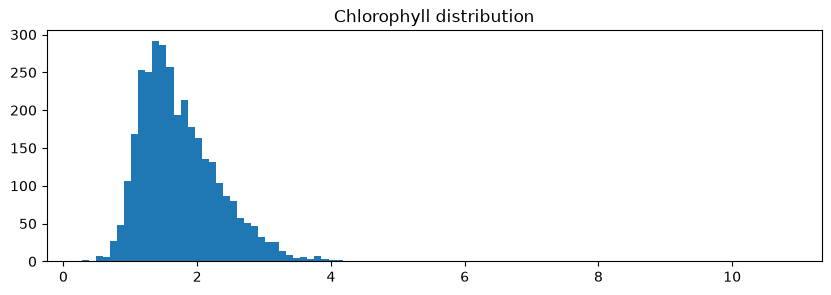

Target statistics:
count    3287.000000
mean        1.747175
std         0.633770
min         0.276926
25%         1.312216
50%         1.624492
75%         2.074589
max        10.811834
Name: chlorophyll_a_mg_m3, dtype: float64

Values above the 99.5th percentile: 17


/var/folders/kt/fyg0570x43n_4dyk_g23txpw0000gn/T/ipykernel_23371/1817225576.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False)
/var/folders/kt/fyg0570x43n_4dyk_g23txpw0000gn/T/ipykernel_23371/1817225576.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False)
/var/folders/kt/fyg0570x43n_4dyk_g23txpw0000gn/T/ipykernel_23371/1817225576.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False)
/var/folders/kt/fyg0570x43n_4dyk_g23txpw0000gn/T/ipykernel_23371/1817225576.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed 

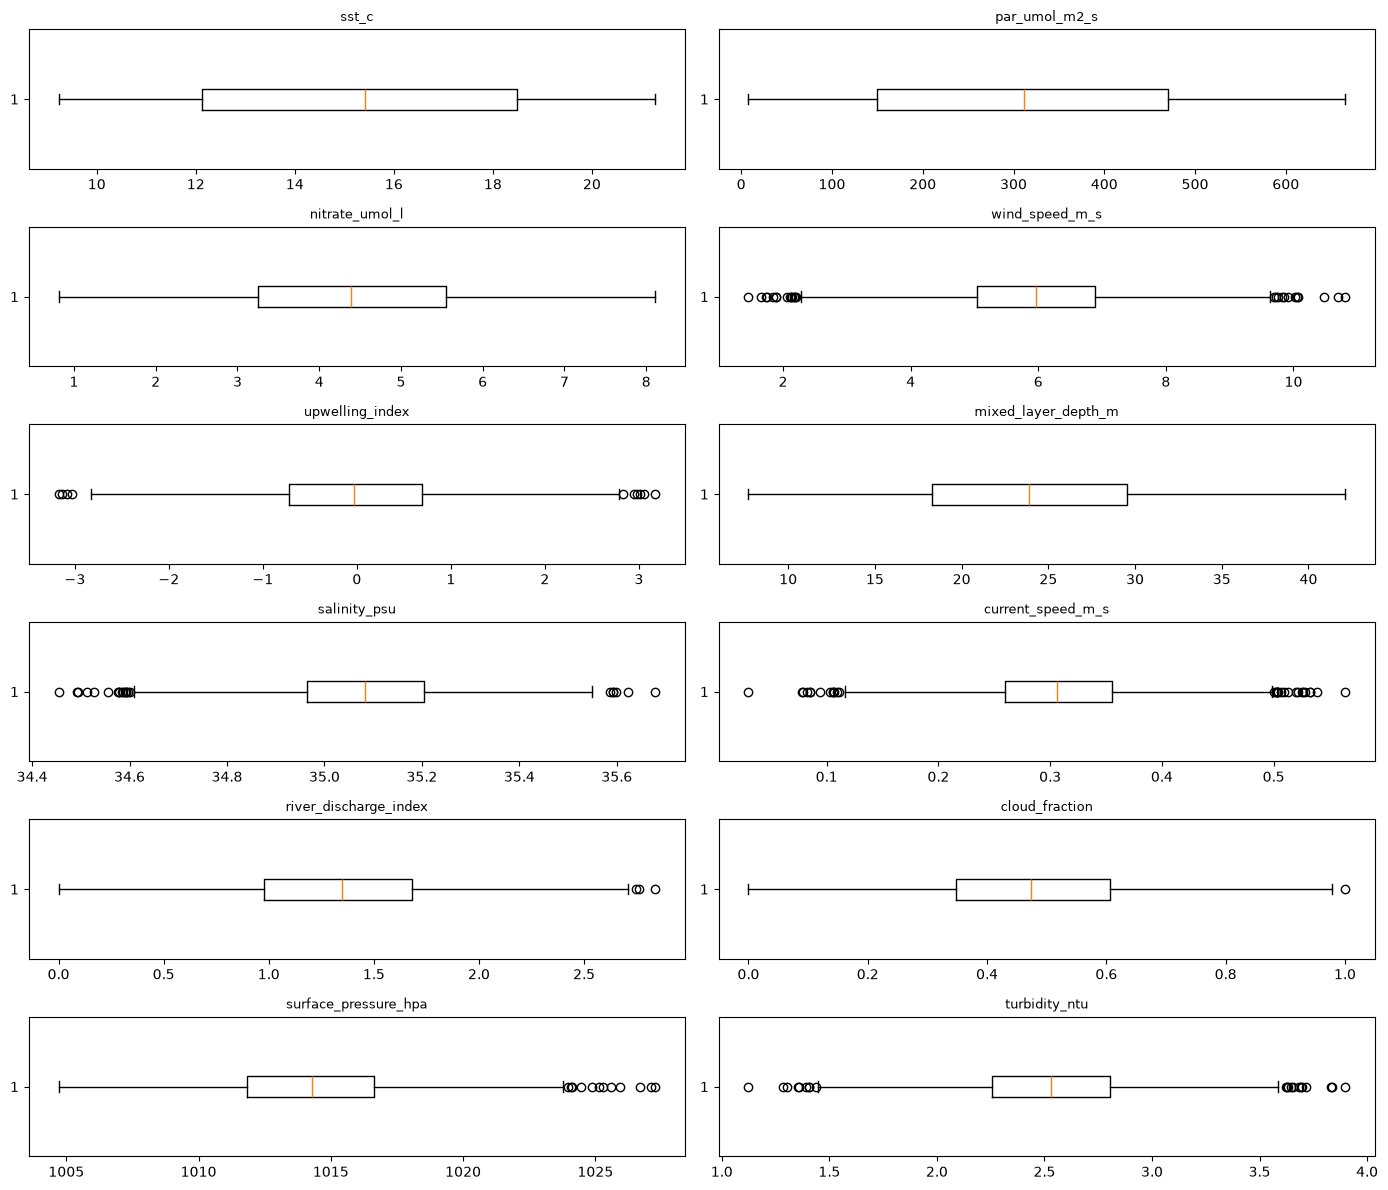

In [91]:
# 1) Target distribution and extreme values
plt.figure(figsize=(10, 3))
plt.hist(df["chlorophyll_a_mg_m3"], bins=100)
plt.title("Chlorophyll distribution")
plt.show()

print("Target statistics:")
print(df["chlorophyll_a_mg_m3"].describe())
print("\nValues above the 99.5th percentile:",
      (df["chlorophyll_a_mg_m3"] > df["chlorophyll_a_mg_m3"].quantile(0.995)).sum())

# 2) Distribution of each exogenous variable: sudden spikes = retrieval errors
fig, axes = plt.subplots(6, 2, figsize=(14, 12))
for ax, col in zip(axes.flat, exo_cols):
    ax.boxplot(df[col], vert=False)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

## Cell 6 - Lagged feature construction (default lag spec)

In [92]:
lagged = build_lagged_frame(df, lag_spec=DEFAULT_LAGS)
print("Rows, columns:", lagged.shape)

feature_cols = [c for c in lagged.columns if c not in ("date", "chlorophyll_a_mg_m3")]
X = lagged[feature_cols].to_numpy()
y = lagged["chlorophyll_a_mg_m3"].to_numpy()
print("X:", X.shape, "| y:", y.shape)

Rows, columns: (3273, 135)
X: (3273, 133) | y: (3273,)


## Cell 7 - Chronological split: train up to 2022, validation on 2023

In [93]:
train_mask = lagged["date"] < "2023-01-01"
val_mask = lagged["date"] >= "2023-01-01"

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]

print("Train:", X_train.shape, "| Validation:", X_val.shape)

Train: (2908, 133) | Validation: (365, 133)


## Cell 8 - Explicit standardization (training set only)

In [94]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1.0  # avoid division by zero

X_train_s = (X_train - mu) / sigma
X_val_s = (X_val - mu) / sigma

## Cell 9 - OLS, Ridge, Lasso

In [95]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=20000),
}

results = {}

for name, model in models.items():
    model.fit(X_train_s, y_train)          # intercept estimated by sklearn (fit_intercept=True)
    y_pred = model.predict(X_val_s)
    results[name] = (y_pred, model)

## Cell 10 - Evaluation: R2, RMSE, MAE

In [96]:
def metrics(y_true, y_pred):
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    return r2, rmse, mae

print(f"{'Model':<8} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for name, (y_pred, _) in results.items():
    r2, rmse, mae = metrics(y_val, y_pred)
    print(f"{name:<8} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

Model          R2     RMSE      MAE
OLS        0.5036   0.5471   0.2243
Ridge      0.5037   0.5470   0.2242
Lasso      0.5086   0.5443   0.2181


## Cell 11 - Predictions vs observed (validation 2023)

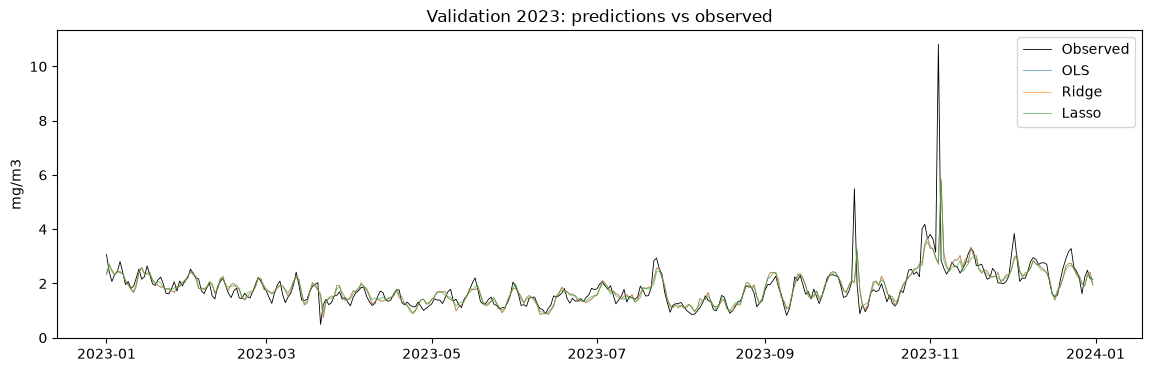

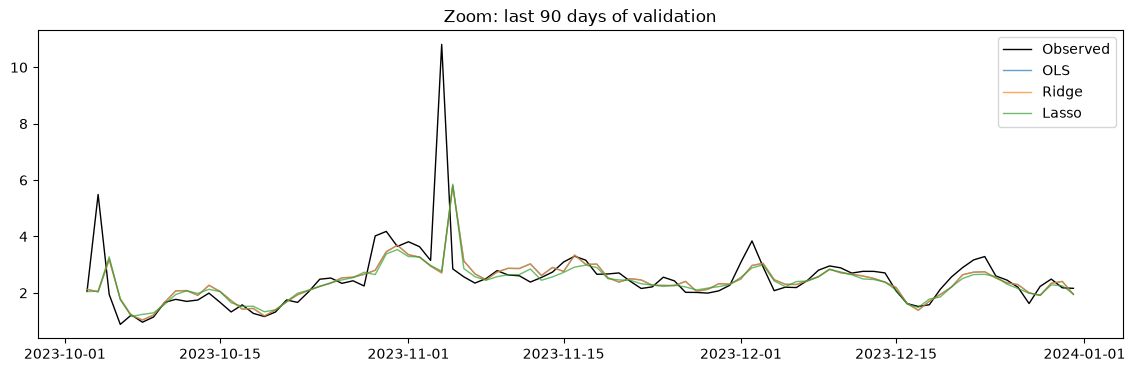

In [97]:
plt.figure(figsize=(14, 4))
plt.plot(lagged["date"][val_mask], y_val, lw=0.6, label="Observed", color="black")
for name, (y_pred, _) in results.items():
    plt.plot(lagged["date"][val_mask], y_pred, lw=0.6, alpha=0.7, label=name)
plt.legend()
plt.title("Validation 2023: predictions vs observed")
plt.ylabel("mg/m3")
plt.show()

# Zoom on the last 90 days
plt.figure(figsize=(14, 4))
plt.plot(lagged["date"][val_mask][-90:], y_val[-90:], lw=1, label="Observed", color="black")
for name, (y_pred, _) in results.items():
    plt.plot(lagged["date"][val_mask][-90:], y_pred[-90:], lw=1, alpha=0.7, label=name)
plt.legend()
plt.title("Zoom: last 90 days of validation")
plt.show()

## Cell 12 - Residual analysis of the best model

Huge isolated errors on the validation set hint at outliers in the data.

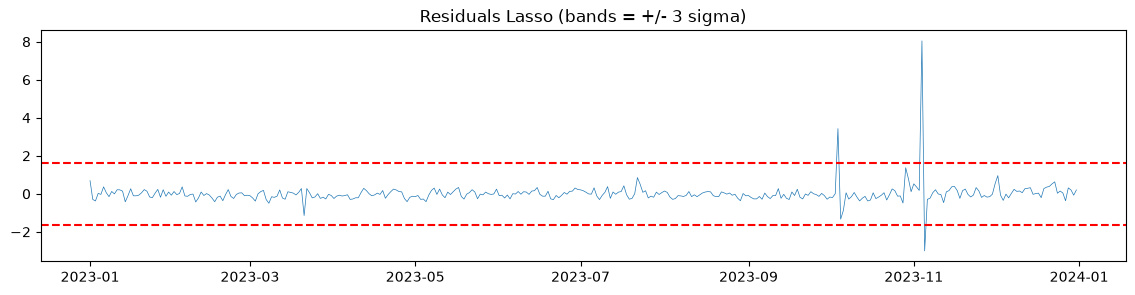

In [98]:
best_name = max(results, key=lambda n: metrics(y_val, results[n][0])[0])
best_model = results[best_name][1]

y_pred_best = results[best_name][0]
residuals = y_val - y_pred_best
plt.figure(figsize=(14, 3))
plt.plot(lagged["date"][val_mask], residuals, lw=0.5)
plt.axhline(3 * residuals.std(), color="red", ls="--")
plt.axhline(-3 * residuals.std(), color="red", ls="--")
plt.title(f"Residuals {best_name} (bands = +/- 3 sigma)")
plt.show()

## Cell 13 - Coefficients of the best model

In [99]:
print(f"Best model: {best_name}")
print(f"Intercept c = {best_model.intercept_:.4f} mg/m3\n")

coefs = pd.Series(best_model.coef_, index=feature_cols)
# Autoregressive coefficients (a_i)
print("Autoregressive coefficients (chlorophyll):")
print(coefs[coefs.index.str.startswith("chlorophyll")].to_string())
print("\nExogenous features with highest |coefficient| (top 20):")
top = (coefs.drop(index=[c for c in coefs.index if c.startswith("chlorophyll")])
            .abs().sort_values(ascending=False).head(20).index)
for c in top:
    print(f"{c}: {coefs[c]:+.4f}")

Best model: Lasso
Intercept c = 1.7382 mg/m3

Autoregressive coefficients (chlorophyll):
chlorophyll_a_mg_m3__lag_1     0.245148
chlorophyll_a_mg_m3__lag_2     0.002348
chlorophyll_a_mg_m3__lag_3     0.000000
chlorophyll_a_mg_m3__lag_4     0.000000
chlorophyll_a_mg_m3__lag_5     0.000000
chlorophyll_a_mg_m3__lag_6     0.002065
chlorophyll_a_mg_m3__lag_7     0.016561
chlorophyll_a_mg_m3__lag_8     0.029057
chlorophyll_a_mg_m3__lag_9     0.000000
chlorophyll_a_mg_m3__lag_10    0.000000
chlorophyll_a_mg_m3__lag_11    0.000000
chlorophyll_a_mg_m3__lag_12    0.002442
chlorophyll_a_mg_m3__lag_13    0.000000
chlorophyll_a_mg_m3__lag_14    0.005971

Exogenous features with highest |coefficient| (top 20):
upwelling_index__lag_2: +0.1114
nitrate_umol_l__lag_3: +0.0949
wind_speed_m_s__lag_1: +0.0610
upwelling_index__lag_3: +0.0600
wind_speed_m_s__lag_2: +0.0164
salinity_psu__lag_4: -0.0114
salinity_psu__lag_2: -0.0073
nitrate_umol_l__lag_4: +0.0051
current_speed_m_s__lag_2: +0.0050
salinity_psu__

## Cell 14 - Alpha tuning for Lasso and Ridge (done manually, no GridSearchCV)

The n.coef!=0 column tells how many features survive: this is the automatic lag/feature selection.

In [100]:
alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

print(f"{'alpha':>7} {'Lasso R2':>10} {'n.coef!=0':>10} {'Ridge R2':>10}")
for a in alphas:
    las = Lasso(alpha=a, max_iter=50000).fit(X_train_s, y_train)
    rid = Ridge(alpha=a).fit(X_train_s, y_train)
    r2_las = metrics(y_val, las.predict(X_val_s))[0]
    r2_rid = metrics(y_val, rid.predict(X_val_s))[0]
    print(f"{a:>7} {r2_las:>10.4f} {(np.abs(las.coef_) > 1e-8).sum():>10} {r2_rid:>10.4f}")

  alpha   Lasso R2  n.coef!=0   Ridge R2
  0.001     0.5119         81     0.5036
  0.003     0.5138         42     0.5036
   0.01     0.5086         20     0.5036
   0.03     0.5007          8     0.5036
    0.1     0.4658          5     0.5036
    0.3     0.2759          3     0.5036
    1.0    -0.0169          0     0.5037
    3.0    -0.0169          0     0.5040
   10.0    -0.0169          0     0.5048


## Cell 15 - Reduced lag ranges (0-4 for all exogenous, guided by the cross-correlation analysis)

The Lasso coefficients and the cross-correlation plots show that almost all the predictive content is at lags 0-4. Retrain with a tighter lag spec.

In [101]:
REDUCED_LAGS = {
    "chlorophyll_a_mg_m3": list(range(1, 6)),
    "sst_c": list(range(0, 5)),
    "par_umol_m2_s": list(range(0, 5)),
    "nitrate_umol_l": list(range(0, 5)),
    "wind_speed_m_s": list(range(0, 5)),
    "upwelling_index": list(range(0, 5)),
    "mixed_layer_depth_m": list(range(0, 5)),
    "salinity_psu": list(range(0, 5)),
    "current_speed_m_s": list(range(0, 5)),
    "river_discharge_index": list(range(0, 5)),
    "cloud_fraction": list(range(0, 5)),
    "surface_pressure_hpa": list(range(0, 5)),
    "turbidity_ntu": list(range(0, 5)),
}

lagged_r = build_lagged_frame(df, lag_spec=REDUCED_LAGS)
feature_cols_r = [c for c in lagged_r.columns if c not in ("date", "chlorophyll_a_mg_m3")]
X_r = lagged_r[feature_cols_r].to_numpy()
y_r = lagged_r["chlorophyll_a_mg_m3"].to_numpy()

train_mask_r = lagged_r["date"] < "2023-01-01"
val_mask_r = lagged_r["date"] >= "2023-01-01"
X_train_r, y_train_r = X_r[train_mask_r], y_r[train_mask_r]
X_val_r, y_val_r = X_r[val_mask_r], y_r[val_mask_r]

# Standardization (training set only)
mu_r = X_train_r.mean(axis=0)
sigma_r = X_train_r.std(axis=0)
sigma_r[sigma_r == 0] = 1.0
X_train_rs = (X_train_r - mu_r) / sigma_r
X_val_rs = (X_val_r - mu_r) / sigma_r

print("Reduced features:", X_train_r.shape[1])

results_r = {}
for name, model in {"OLS": LinearRegression(),
                    "Ridge": Ridge(alpha=1.0),
                    "Lasso": Lasso(alpha=0.01, max_iter=20000)}.items():
    model.fit(X_train_rs, y_train_r)
    results_r[name] = (model.predict(X_val_rs), model)

print(f"\n{'Model':<8} {'R2':>8} {'RMSE':>8} {'MAE':>8}   (reduced lags)")
for name, (y_pred, _) in results_r.items():
    r2, rmse, mae = metrics(y_val_r, y_pred)
    print(f"{name:<8} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

Reduced features: 67

Model          R2     RMSE      MAE   (reduced lags)
OLS        0.5040   0.5469   0.2260
Ridge      0.5040   0.5468   0.2260
Lasso      0.5039   0.5469   0.2223


## Cell 16 - Outlier removal from the training set + retraining

Strategy: identify outlier days from the TRAINING target only, then drop
the corresponding rows from the lagged training matrix.
Thresholds computed on training data only! The validation set is NOT
modified: metrics must be computed on all 2023 days (including outliers),
because the hidden 2024 test will contain its own outliers.

In [102]:
THRESH = 5.0  # mg/m3: look at the histogram, the bulk is below ~4

outlier_mask_train = y_train_r > THRESH
print(f"Training rows dropped as outliers: {outlier_mask_train.sum()} "
      f"({100*outlier_mask_train.mean():.2f}%)")

X_train_o = X_train_rs[~outlier_mask_train]
y_train_o = y_train_r[~outlier_mask_train]

# Retrain on cleaned data (reduced lags, standardized on cleaned training set)
mu_o = X_train_o.mean(axis=0)
sigma_o = X_train_o.std(axis=0)
sigma_o[sigma_o == 0] = 1.0
X_train_os = (X_train_o - mu_o) / sigma_o
X_val_os = (X_val_r - mu_o) / sigma_o

results_o = {}
for name, model in {"OLS": LinearRegression(),
                    "Ridge": Ridge(alpha=1.0),
                    "Lasso": Lasso(alpha=0.003, max_iter=50000)}.items():
    model.fit(X_train_os, y_train_o)
    results_o[name] = (model.predict(X_val_os), model)

print(f"\n{'Model':<8} {'R2':>8} {'RMSE':>8} {'MAE':>8}   (outliers removed, reduced lags)")
for name, (y_pred, _) in results_o.items():
    r2, rmse, mae = metrics(y_val_r, y_pred)
    print(f"{name:<8} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

Training rows dropped as outliers: 3 (0.10%)

Model          R2     RMSE      MAE   (outliers removed, reduced lags)
OLS      -4792.9408  53.7631  46.7661
Ridge    -4643.4982  52.9185  46.0338
Lasso    -63.9992   6.2603   5.7058


## Cell 17 - Visual comparison after cleaning

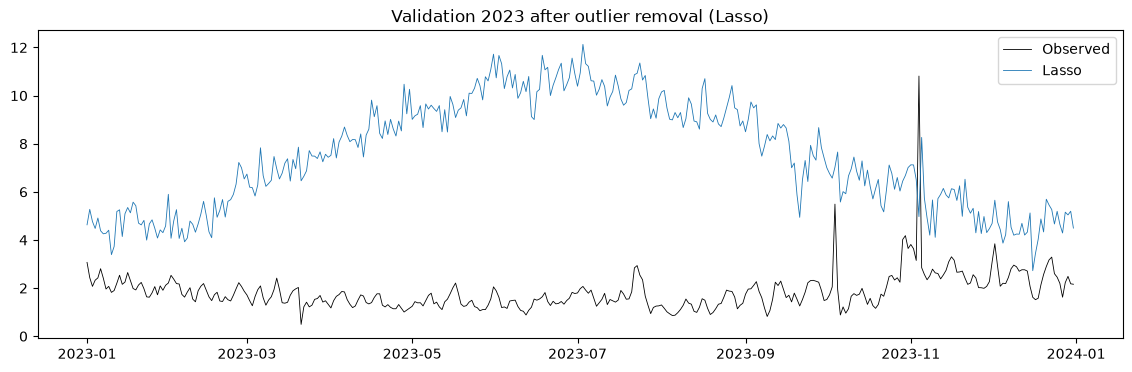

In [103]:
best_o = max(results_o, key=lambda n: metrics(y_val_r, results_o[n][0])[0])
plt.figure(figsize=(14, 4))
plt.plot(lagged_r["date"][val_mask_r], y_val_r, lw=0.6, color="black", label="Observed")
plt.plot(lagged_r["date"][val_mask_r], results_o[best_o][0], lw=0.6, label=best_o)
plt.legend()
plt.title(f"Validation 2023 after outlier removal ({best_o})")
plt.show()

## Cell 18 - Outlier threshold sweep (drop strategy)

Try THRESH = 4.0, 5.0, 6.0 plus a sigma-based rule (mean + 3/4/5 sigma)
and keep the value that maximizes R2 on the validation set.

In [104]:
def train_eval_outlier_drop(thresh):
    """Drop training rows with target above thresh, retrain Lasso, return metrics."""
    mask = y_train_r <= thresh
    X_tr, y_tr = X_train_rs[mask], y_train_r[mask]
    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0)
    sd[sd == 0] = 1.0
    model = Lasso(alpha=0.003, max_iter=50000).fit((X_tr - mu) / sd, y_tr)
    y_pred = model.predict((X_val_r - mu) / sd)
    return metrics(y_val_r, y_pred)

mean_tr, std_tr = y_train_r.mean(), y_train_r.std()
thresholds = [4.0, 5.0, 6.0, mean_tr + 3*std_tr, mean_tr + 4*std_tr, mean_tr + 5*std_tr]

print(f"{'threshold':>10} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for t in thresholds:
    r2, rmse, mae = train_eval_outlier_drop(t)
    print(f"{t:>10.2f} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

 threshold       R2     RMSE      MAE
      4.00 -88.3538   7.3400   6.9871
      5.00 -63.9992   6.2603   5.7058
      6.00 -63.9992   6.2603   5.7058
      3.57 -54.5386   5.7868   5.4378
      4.19 -73.0892   6.6837   6.2845
      4.80 -63.9992   6.2603   5.7058


## Cell 19 - Winsorizing (clip instead of drop)

Instead of dropping rows, clip the training target at the threshold.
Often better than removal: the exogenous information of those days is kept.

In [105]:
def train_eval_winsorize(thresh):
    """Clip training target at thresh, retrain Lasso, return metrics."""
    y_tr = np.clip(y_train_r, None, thresh)
    mu = X_train_rs.mean(axis=0)
    sd = X_train_rs.std(axis=0)
    sd[sd == 0] = 1.0
    model = Lasso(alpha=0.003, max_iter=50000).fit((X_train_rs - mu) / sd, y_tr)
    y_pred = model.predict((X_val_r - mu) / sd)
    return metrics(y_val_r, y_pred)

print(f"{'clip at':>10} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for t in [3.0, 4.0, 5.0, 6.0]:
    r2, rmse, mae = train_eval_winsorize(t)
    print(f"{t:>10.2f} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

   clip at       R2     RMSE      MAE
      3.00 -27.7149   4.1609   4.0441
      4.00 -83.5992   7.1420   6.7722
      5.00 -77.1076   6.8625   6.5364
      6.00 -84.3379   7.1731   6.9105


## Cell 20 - Clipping outliers in the exogenous features too

Boxplots show isolated spikes in some exogenous variables. Clip each
feature at its training 0.5th and 99.5th percentiles (train only!),
then retrain. Combined with target winsorizing.

In [106]:
def train_eval_clip_all(target_clip, exo_p=0.995):
    """Clip exogenous features at train percentiles and winsorize the target."""
    lo = np.percentile(X_train_r, (1-exo_p)*100, axis=0)
    hi = np.percentile(X_train_r, exo_p*100, axis=0)
    X_tr = np.clip(X_train_r, lo, hi)
    X_va = np.clip(X_val_r, lo, hi)   # same TRAINING limits applied to validation
    y_tr = np.clip(y_train_r, None, target_clip)

    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0)
    sd[sd == 0] = 1.0
    model = Lasso(alpha=0.003, max_iter=50000).fit((X_tr - mu) / sd, y_tr)
    y_pred = model.predict((X_va - mu) / sd)
    return metrics(y_val_r, y_pred)

print(f"{'tgt clip':>9} {'R2':>8} {'RMSE':>8} {'MAE':>8}   (exo clipped at 0.5/99.5 pct)")
for t in [4.0, 5.0, 6.0]:
    r2, rmse, mae = train_eval_clip_all(t)
    print(f"{t:>9.2f} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

 tgt clip       R2     RMSE      MAE   (exo clipped at 0.5/99.5 pct)
     4.00   0.5653   0.5120   0.2060
     5.00   0.5656   0.5118   0.2059
     6.00   0.5656   0.5118   0.2061


## Cell 21 - Log transformation of the target

The target is right-skewed. Train on log(y) and predict exp(...).
The target transformation is written explicitly in code, as required
by the project rules. Metrics are computed in the ORIGINAL mg/m3 scale.

In [107]:
def train_eval_log(target_clip=None):
    """Train Lasso on log(y), return metrics in the original scale."""
    if target_clip is not None:
        y_tr = np.clip(y_train_r, None, target_clip)
    else:
        y_tr = y_train_r
    log_y_tr = np.log(y_tr)   # y > 0 always (min is ~0.28)

    mu = X_train_rs.mean(axis=0)
    sd = X_train_rs.std(axis=0)
    sd[sd == 0] = 1.0
    model = Lasso(alpha=0.003, max_iter=50000).fit((X_train_rs - mu) / sd, log_y_tr)
    y_pred = np.exp(model.predict((X_val_r - mu) / sd))   # explicit inverse transform
    return metrics(y_val_r, y_pred)

print(f"{'variant':<22} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for label, tc in [("log, no clip", None), ("log, clip at 5.0", 5.0)]:
    r2, rmse, mae = train_eval_log(tc)
    print(f"{label:<22} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

variant                      R2     RMSE      MAE
log, no clip           -56.9565   5.9114   5.6164
log, clip at 5.0       -20.4457   3.5959   3.4042


## Cell 22 - Refining the winning recipe (exo clipping + target winsorizing)

Sweep the exogenous clipping percentile, the target clip, the alpha and
the model type around the Cell 20 winner.

In [108]:
def train_eval_full(exo_p, target_clip, alpha, model_class):
    """Clip exo at train percentiles, winsorize target, retrain, return metrics."""
    lo = np.percentile(X_train_r, (1-exo_p)*100, axis=0)
    hi = np.percentile(X_train_r, exo_p*100, axis=0)
    X_tr = np.clip(X_train_r, lo, hi)
    X_va = np.clip(X_val_r, lo, hi)      # same TRAINING limits
    y_tr = np.clip(y_train_r, None, target_clip)

    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0)
    sd[sd == 0] = 1.0
    model = model_class(alpha=alpha, max_iter=50000).fit((X_tr - mu) / sd, y_tr)
    y_pred = model.predict((X_va - mu) / sd)
    return metrics(y_val_r, y_pred), (y_pred, model, lo, hi, mu, sd)

results_full = {}
print(f"{'exo_p':>6} {'tgt':>5} {'alpha':>7} {'model':<7} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for exo_p in [0.99, 0.995, 0.999]:
    for tgt in [4.0, 5.0, None]:
        for alpha, cls in [(0.003, Lasso), (0.01, Lasso), (1.0, Ridge), (0.1, Ridge)]:
            label = f"{exo_p}|{tgt}|{alpha}|{cls.__name__}"
            (r2, rmse, mae), _ = train_eval_full(exo_p, tgt if tgt else 99.0, alpha, cls)
            results_full[label] = (r2, rmse, mae)
            print(f"{exo_p:>6} {tgt if tgt else 'none':>5} {alpha:>7} {cls.__name__:<7} "
                  f"{r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

best_label = max(results_full, key=lambda k: results_full[k][0])
print(f"\nBest configuration: {best_label} -> R2 = {results_full[best_label][0]:.4f}")

 exo_p   tgt   alpha model         R2     RMSE      MAE
  0.99   4.0   0.003 Lasso     0.5658   0.5117   0.2060
  0.99   4.0    0.01 Lasso     0.5602   0.5149   0.2085
  0.99   4.0     1.0 Ridge     0.5652   0.5120   0.2067
  0.99   4.0     0.1 Ridge     0.5652   0.5120   0.2067
  0.99   5.0   0.003 Lasso     0.5662   0.5114   0.2060
  0.99   5.0    0.01 Lasso     0.5610   0.5145   0.2084
  0.99   5.0     1.0 Ridge     0.5659   0.5116   0.2067
  0.99   5.0     0.1 Ridge     0.5660   0.5116   0.2067
  0.99  none   0.003 Lasso     0.5662   0.5114   0.2068
  0.99  none    0.01 Lasso     0.5624   0.5136   0.2084
  0.99  none     1.0 Ridge     0.5670   0.5110   0.2077
  0.99  none     0.1 Ridge     0.5670   0.5109   0.2077
 0.995   4.0   0.003 Lasso     0.5653   0.5120   0.2060
 0.995   4.0    0.01 Lasso     0.5604   0.5148   0.2082
 0.995   4.0     1.0 Ridge     0.5637   0.5129   0.2067
 0.995   4.0     0.1 Ridge     0.5637   0.5129   0.2067
 0.995   5.0   0.003 Lasso     0.5656   0.5118  

## Cell 23 - Drop vs winsorize for the target, both with exo clipping

In [109]:
def train_eval_drop_exoclip(exo_p, thresh, alpha=0.003):
    """Clip exo at train percentiles, DROP rows with target above thresh."""
    lo = np.percentile(X_train_r, (1-exo_p)*100, axis=0)
    hi = np.percentile(X_train_r, exo_p*100, axis=0)
    X_tr_full = np.clip(X_train_r, lo, hi)
    X_va = np.clip(X_val_r, lo, hi)
    mask = y_train_r <= thresh
    X_tr, y_tr = X_tr_full[mask], y_train_r[mask]

    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0)
    sd[sd == 0] = 1.0
    model = Lasso(alpha=alpha, max_iter=50000).fit((X_tr - mu) / sd, y_tr)
    y_pred = model.predict((X_va - mu) / sd)
    return metrics(y_val_r, y_pred)

print(f"{'exo_p':>6} {'drop>':>6} {'R2':>8} {'RMSE':>8} {'MAE':>8}")
for exo_p in [0.995, 0.999]:
    for thresh in [5.0, 6.0]:
        r2, rmse, mae = train_eval_drop_exoclip(exo_p, thresh)
        print(f"{exo_p:>6} {thresh:>6.1f} {r2:>8.4f} {rmse:>8.4f} {mae:>8.4f}")

 exo_p  drop>       R2     RMSE      MAE
 0.995    5.0   0.5655   0.5118   0.2058
 0.995    6.0   0.5655   0.5118   0.2058
 0.999    5.0   0.5562   0.5173   0.2101
 0.999    6.0   0.5562   0.5173   0.2101
